# Grammy 2027: Stage 1 reproducible report
Team: Yegor Lazarev, Alexander Shayko, Diana Shilova.

Eight Bayesian probit nomination models, 27 predictors, v4 binary center-only scaling. Evaluation uses seasons **2024 and 2025** (16 fits); season 2026 is the 2027 forecast (8 fits). All fits use 600 warmup, target acceptance .99 and two chains; retained draws per chain are 500 for 2024 and 1500 for 2025/2026.

**Data status:** the verified results below use the original snapshot. Chat B found two false-negative AOTY labels and a Silk Sonic identity issue. Original results are an auditable reference, not forecasts fitted to corrected data. See DATA_CHANGES.md. No MCMC was run during this report cleanup.

Default `RUN_MODE="replay"` validates the supplied export hashes, checks keys and baseline rates against the source data, and recalculates the report without JAX or training. `RUN_MODE="fit"` uses the original cache signatures; `ALLOW_TRAINING=False` stops at a missing exact cache. Change it only when intentionally starting training. Original displayed outputs are retained only in original_executed.ipynb, not mixed into this notebook.

The target is association of a named artist with a nomination, not a work-level nominee or an official recipient. Stage 2/3 is a separate, incomplete experiment.


## 1. Environment
Replay requires numpy, pandas, scipy and matplotlib. JAX/NumPyro are imported only when fit mode is selected. Keep Kaggle's GPU-enabled JAX installation. Runtime and original sampling versions are recorded separately.


In [1]:
# Optional, only if dependencies are missing:
# %pip install numpyro pandas scipy matplotlib


In [2]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
import gc, gzip, hashlib, json, time, warnings
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import ndtr, ndtri, log_ndtr as scipy_log_ndtr
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
try:
    from IPython.display import display
except ImportError:
    def display(x): print(x)
VERSIONS = {p: metadata.version(p) for p in ["numpy", "pandas", "scipy", "matplotlib"]}


## 2. Configuration and information set
Training always uses seasons strictly earlier than the forecast season. Two test seasons give only two annual comparisons; category events and artist rows are dependent. The choice of two seasons followed earlier exploratory work and is not an untouched prospective test.

The source's October–September chart window is a proxy. The final chart cutoff is 2026-09-30; publication dates of historical award features remain unaudited. This is a retrospectively assembled backtest, not a fully reconstructed real-time dataset.

The [Recording Academy calendar](https://www.grammy.com/news/2027-grammys-show-air-date-nominations-announced/) gives nominations on 2026-11-16 and ceremony on 2027-02-07. Its [submission guide](https://www.grammy.com/news/2027-grammys-how-submit-music-guide/) specifies product eligibility 2025-08-31 through 2026-08-28 (checked 2026-10-22). Chart observation cutoff and release eligibility are different concepts. September chart observations can be known before nominations, but they do not establish eligibility. The snapshot lacks dated work IDs/releases, so no candidate-level eligibility filter is justified from these rows alone. From chart cutoff the nomination horizon is 47 days; from this report's date it is 25 days.


In [3]:
# Edit paths/mode here only. Replay never trains.
RUN_MODE = "replay"  # "replay" or "fit"
DATA_VARIANT = "original"  # "original" or "label_fixes_v1" (Silk Sonic still unresolved)
ALLOW_TRAINING = False
BASE = Path(".")  # directory containing data/, exports_stage1/, posterior_cache/
EXPORT_INPUT = BASE / "exports_stage1"
assert RUN_MODE in {"replay", "fit"}
KAGGLE_INPUT = Path("/kaggle/input/datasets/shaykoaleksandr/grammy-dataset/Grammy Nomination Dataset.csv")
INPUT_PATH = KAGGLE_INPUT if KAGGLE_INPUT.is_file() else None
if DATA_VARIANT == "label_fixes_v1":
    INPUT_PATH = BASE / "data_corrections/grammy_label_fixes_v1.csv"
    if RUN_MODE == "replay":
        raise ValueError("Corrected data have no fitted exports. Choose fit mode deliberately.")
FORECAST_SEASON = 2026
TEST_SEASONS = [2024, 2025]
TOP_K = 5
SEED = 20261021
NUM_WARMUP = 600
NUM_SAMPLES = 500
NUM_CHAINS = 2
TARGET_ACCEPT = 0.99
MAX_TREE_DEPTH = 10
ALPHA_LOCATION = float(ndtri(0.01))
ALPHA_SCALE = 1.0
BETA_SCALE = 1.0
MAX_RHAT = 1.05
MIN_ESS = 100
MAP_GRAD_TOLERANCE = 1e-4
MODEL_VERSION = "compact27-binary-unscaled-v4"
LATE_SEASON_SAMPLES = 1500
PRECONDITIONER = "fixed inverse posterior Hessian at training MAP"
if RUN_MODE == "fit":
    import jax
    jax.config.update("jax_enable_x64", True)
    import jax.numpy as jnp
    from jax.scipy.special import log_ndtr
    import numpyro
    import numpyro.distributions as dist
    from numpyro.infer import MCMC, NUTS, init_to_value
    from numpyro.diagnostics import summary as mcmc_summary
    VERSIONS.update({p: metadata.version(p) for p in ["jax", "jaxlib", "numpyro"]})
    CHAIN_METHOD = "parallel" if jax.default_backend() == "gpu" and jax.local_device_count() >= NUM_CHAINS else "sequential"
else:
    CHAIN_METHOD = "not used: verified export replay"

CATEGORIES = ["album_of_the_year", "record_of_the_year", "song_of_the_year",
              "best_new_artist", "pop_vocal_album", "pop_solo",
              "pop_duo_group", "music_video"]

# Source category stems used to define relevant award recognition.
# Empty lists mean no direct counterpart; the corresponding feature is zero.
RELEVANT_AWARD_STEMS = {
    "ama": {
        "album_of_the_year": ["album_of_the_year", "pop_album"],
        "record_of_the_year": ["song_of_the_year", "pop_song", "collaboration_of_the_year"],
        "song_of_the_year": ["song_of_the_year", "pop_song", "collaboration_of_the_year"],
        "best_new_artist": ["new_artist_of_the_year"],
        "pop_vocal_album": ["pop_album", "album_of_the_year"],
        "pop_solo": ["pop_song", "pop_male_artist", "pop_female_artist"],
        "pop_duo_group": ["pop_duo_group", "collaboration_of_the_year"],
        "music_video": ["music_video"],
    },
    "vma": {
        "album_of_the_year": [],
        "record_of_the_year": ["song_of_the_year", "best_pop", "best_collaboration"],
        "song_of_the_year": ["song_of_the_year", "best_pop", "best_collaboration"],
        "best_new_artist": ["best_new_artist"],
        "pop_vocal_album": ["best_pop"],
        "pop_solo": ["best_pop", "best_male_video", "best_female_video"],
        "pop_duo_group": ["best_group", "best_collaboration"],
        "music_video": ["video_of_the_year"],
    },
    "iheart": {
        "album_of_the_year": [],
        "record_of_the_year": ["song_of_the_year", "pop_song_of_the_year", "best_collaboration"],
        "song_of_the_year": ["song_of_the_year", "pop_song_of_the_year", "best_collaboration"],
        "best_new_artist": ["best_new_artist", "best_new_pop_artist"],
        "pop_vocal_album": ["pop_artist_of_the_year"],
        "pop_solo": ["pop_song_of_the_year", "pop_artist_of_the_year", "male_artist_of_the_year", "female_artist_of_the_year"],
        "pop_duo_group": ["duo_group_of_the_year", "best_collaboration"],
        "music_video": ["best_music_video"],
    },
}

OUTPUT = Path("/kaggle/working/stage1_report") if Path("/kaggle/working").is_dir() else BASE / "report_outputs"
CACHE = OUTPUT / "posterior_cache"  # Writable location for new fits.
LEGACY_CACHE = BASE / "posterior_cache"  # Read-only legacy caches are also supported.
CACHE.mkdir(parents=True, exist_ok=True)
OUTPUT.mkdir(parents=True, exist_ok=True)
if NUM_CHAINS < 2:
    raise ValueError("Use at least two chains for convergence checks.")
if not TEST_SEASONS or max(TEST_SEASONS) >= FORECAST_SEASON:
    raise ValueError("Test seasons must precede the forecast season.")
print("Chain execution:", CHAIN_METHOD, "| planned fits:", len(CATEGORIES)*(len(TEST_SEASONS)+1))
print("Output:", OUTPUT.resolve())


Chain execution: not used: verified export replay | planned fits: 24
Output: /workspace/scratch/14888983397b/deliverables/stage1_package/report_outputs


## 3. Input and integrity checks

The supplied dataset was built by `grammy_nomination_dataset.ipynb`. Its inputs include Billboard chart snapshots, the Grammy label/performer files, and the prepared AMA, VMA and iHeartRadio tables supplied with the project. Their seasonal alignment is retained without another lag. The preparation notebook and raw inputs are preserved in `source_project/` in the archive for provenance; this model notebook does not need to download data.

The SHA-256 below identifies the **decompressed CSV bytes** used for this run. If the dataset is intentionally revised, audit the revision and update the expected hash explicitly. Final-season labels must remain missing. `won` is never a predictor.

References: [Billboard source archive](https://github.com/utdata/rwd-billboard-data/tree/f5801b03d5e629845e65213ff236df98f1aae3fd), [Grammy awards archive](https://www.grammy.com/awards), [NumPyro documentation](https://num.pyro.ai/en/stable/). The exact provenance and extraction methods for the supplemental label files still need verification before the final course submission.


In [4]:
EXPECTED_SHA256 = "f2f8a3af293485500c7a792ed333bffaf7671aa075ef49f4f193633bb9d6b62c"
if DATA_VARIANT == "label_fixes_v1":
    EXPECTED_SHA256 = json.loads((BASE/"data_corrections/change_manifest.json").read_text())["corrected_sha256"]
candidates = ([Path(INPUT_PATH)] if INPUT_PATH is not None else [
    BASE / Path("data/grammy_nomination_dataset.csv.gz"),
    BASE / Path("data/grammy_nomination_dataset.csv"),
    Path("Grammy Nomination Dataset.csv"),
    Path("grammy_nomination_dataset.csv"),
])
DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Extract the archive or set INPUT_PATH to the supplied CSV.")
opener = gzip.open if DATA_PATH.suffix == ".gz" else open
with opener(DATA_PATH, "rb") as f:
    DATA_SHA256 = hashlib.file_digest(f, "sha256").hexdigest()
if DATA_SHA256 != EXPECTED_SHA256:
    raise ValueError("Input differs from the audited dataset. Review it before changing EXPECTED_SHA256.")
data = pd.read_csv(DATA_PATH)
INPUT_SHAPE = data.shape
AWARD_TOTAL_COLUMNS = ["ama_noms_total", "ama_wins_prev_total",
                       "vma_noms_total", "vma_wins_total",
                       "iheart_noms_total", "iheart_wins_total"]
AWARD_HELD_COLUMNS = ["ama_held", "vma_held", "iheart_held"]
AWARD_FLAG_SUFFIXES = ("_ama_nominated", "_ama_winner_prev",
                       "_vma_nominated", "_vma_winner",
                       "_iheart_nominated", "_iheart_winner")
AWARD_FLAG_COLUMNS = sorted(c for c in data.columns if c.endswith(AWARD_FLAG_SUFFIXES))
AWARD_COLUMNS = AWARD_FLAG_COLUMNS + AWARD_TOTAL_COLUMNS + AWARD_HELD_COLUMNS
if len(AWARD_FLAG_COLUMNS) != 62 or len(set(AWARD_COLUMNS)) != 71:
    raise ValueError("Expected 62 award-category flags, six totals and three ceremony indicators.")
missing_award_columns = sorted(set(AWARD_COLUMNS) - set(data.columns))
if missing_award_columns:
    raise ValueError(f"Missing prepared award features: {missing_award_columns}")
MODEL_COLUMNS = ["season", "cat", "artist_key", "artist", "nominated",
                 "h_best_peak", "b_best_peak", "h_entries", "b_entries",
                 "h_weeks", "b_weeks", "h_top10_weeks", "b_top10_weeks",
                 "prior_noms", "prior_wins", "prior_noms_same_cat", "new_in_window"] + AWARD_COLUMNS
data = data[MODEL_COLUMNS].copy()  # retain only model columns to reduce memory usage
keys = ["season", "cat", "artist_key"]
if data[keys].isna().any().any() or data.duplicated(keys).any():
    raise ValueError("Missing or duplicated artist-season-category keys.")
if set(data.cat) != set(CATEGORIES):
    raise ValueError("Unexpected categories.")
data = data.sort_values(keys).reset_index(drop=True)
historical = data.loc[data.season < FORECAST_SEASON].copy()
future = data.loc[data.season == FORECAST_SEASON].copy()
if historical.nominated.isna().any() or not historical.nominated.isin([0, 1]).all():
    raise ValueError("Historical nomination labels must be binary and complete.")
if future.empty or future.nominated.notna().any():
    raise ValueError("Forecast-season outcomes must be unavailable.")
if not set(TEST_SEASONS).issubset(set(historical.season)):
    raise ValueError("A requested test season is absent.")
print("Input:", DATA_PATH, "| source shape:", INPUT_SHAPE, "| SHA-256:", DATA_SHA256)
display(historical.groupby("cat").agg(
    observations=("nominated", "size"), nominated_artists=("nominated", "sum"),
    seasons=("season", "nunique"), nomination_rate=("nominated", "mean")))
display(data.groupby("season").agg(rows=("artist_key", "size"),
                                  observed_labels=("nominated", "count")))


Input: data/grammy_nomination_dataset.csv.gz | source shape: (203944, 95) | SHA-256: f2f8a3af293485500c7a792ed333bffaf7671aa075ef49f4f193633bb9d6b62c


,observations,nominated_artists,seasons,nomination_rate
cat,,,,
album_of_the_year,24855,152.0,26,0.006115
best_new_artist,24855,142.0,26,0.005713
music_video,24855,129.0,26,0.005190
pop_duo_group,24855,268.0,26,0.010783
pop_solo,24855,177.0,26,0.007121
pop_vocal_album,24855,127.0,26,0.005110
record_of_the_year,24855,189.0,26,0.007604
song_of_the_year,24855,184.0,26,0.007403


,rows,observed_labels
season,,
2000,5840,5840
2001,6136,6136
2002,6400,6400
2003,6792,6792
2004,6968,6968
2005,7032,7032
2006,7608,7608
2007,8240,8240
2008,8672,8672


## 4. Aggregating other-award information

The original 12 chart/Grammy predictors are retained: chart peak strength, log entries/weeks/top-10 weeks for each chart, log prior Grammy nominations/wins/category nominations, and the existing new-in-window flag.

The other 71 columns are replaced by **15 predictors**:

| Group | Count | Construction |
|---|---:|---|
| Overall recognition at each award | 6 | Existing total nominations and wins, transformed with `log1p` |
| Ceremony presence | 3 | Existing `ama_held`, `vma_held`, `iheart_held` |
| Recognition relevant to the target category | 6 | Any nomination and any win in the source categories listed in `RELEVANT_AWARD_STEMS`, for each award |

For example, Best New Artist uses new-artist recognition, Music Video uses music-video recognition, and Pop Duo/Group uses group/collaboration recognition. For Album of the Year, VMA/iHeart have no direct album counterpart in this input: their relevant-category flags are zero, while their overall recognition totals remain available. For Pop Vocal Album, pop-performance/artist awards are broad proxies, not equivalent album awards. The mapping is a prespecified modelling judgement, not an official equivalence of award categories.

An `any` indicator uses a maximum, rather than summing overlapping category flags. The global totals describe broad recognition; the relevant flags preserve some target-specific information that totals alone would discard. Aggregation intentionally discards some fine detail; whether this helps prediction must be evaluated by the backtest. This revision is not statistically identical to the former 83-predictor specification.

**Timing is preserved:** current mapped-season nominations for all three awards, current VMA/iHeart winners, and already-lagged most-recent-earlier-ceremony AMA winners. There is no additional annual shift. Current `ama_held` does not erase earlier AMA wins. The supplied availability convention is adopted; historical publication dates have not been independently re-audited.

Continuous predictors use training means and standard deviations. Binary predictors are centered on training means but use scale one; constant continuous columns also use scale one. The model uses 27 coefficients plus an intercept. Normal priors regularize remaining dependence between totals and relevant-category flags. No class weighting or negative-class subsampling is introduced.


In [5]:
def make_features(frame):
    out = pd.DataFrame(index=frame.index)
    for prefix, size in [("h", 100), ("b", 200)]:
        peak = frame[f"{prefix}_best_peak"]
        if not peak.dropna().between(1, size).all():
            raise ValueError(f"Invalid {prefix} chart peak.")
        out[f"{prefix}_peak_strength"] = ((size + 1 - peak) / size).fillna(0)
        for field in ["entries", "weeks", "top10_weeks"]:
            name = f"{prefix}_{field}"
            if frame[name].isna().any() or (frame[name] < 0).any():
                raise ValueError(f"Invalid chart counts: {name}")
            out[f"log_{name}"] = np.log1p(frame[name])
    for name in ["prior_noms", "prior_wins", "prior_noms_same_cat"]:
        if frame[name].isna().any() or (frame[name] < 0).any():
            raise ValueError(f"Invalid Grammy history: {name}")
        out[f"log_{name}"] = np.log1p(frame[name])
    if not frame.new_in_window.isin([0, 1]).all():
        raise ValueError("new_in_window must be binary.")
    out["new_in_window"] = frame.new_in_window.astype(float)

    # Check all source columns even though they are aggregated below.
    for name in AWARD_FLAG_COLUMNS + AWARD_HELD_COLUMNS:
        if not frame[name].isin([0, 1]).all():
            raise ValueError(f"Invalid award indicator: {name}")
    for name in AWARD_TOTAL_COLUMNS:
        values = frame[name]
        if values.isna().any() or (values < 0).any() or not np.equal(values, np.floor(values)).all():
            raise ValueError(f"Invalid award count: {name}")
        out[f"log_{name}"] = np.log1p(values)
    for name in AWARD_HELD_COLUMNS:
        out[name] = frame[name].astype(float)

    for award, mapping in RELEVANT_AWARD_STEMS.items():
        if set(mapping) != set(CATEGORIES):
            raise ValueError(f"Incomplete category mapping: {award}")
        for kind, source_suffix in [("nominated", "nominated"),
                                    ("winner", "winner_prev" if award == "ama" else "winner")]:
            feature = f"{award}_relevant_{kind}"
            out[feature] = 0.0
            for cat, stems in mapping.items():
                columns = [f"{stem}_{award}_{source_suffix}" for stem in stems]
                if columns:
                    mask = frame.cat.eq(cat)
                    out.loc[mask, feature] = frame.loc[mask, columns].max(axis=1).astype(float)
    if out.shape[1] != 27 or not np.isfinite(out.to_numpy()).all():
        raise ValueError("Expected 27 finite predictors.")
    return out

FEATURE_NAMES = make_features(data.head(10)).columns.tolist()

def training_scaler(frame):
    features = make_features(frame)
    raw = features.to_numpy(dtype=float)

    center = raw.mean(axis=0)
    scale = raw.std(axis=0, ddof=0)
    scale = np.where(scale < 1e-12, 1.0, scale)

    binary_features = {
        "new_in_window",
        "ama_held",
        "vma_held",
        "iheart_held",
        "ama_relevant_nominated",
        "ama_relevant_winner",
        "vma_relevant_nominated",
        "vma_relevant_winner",
        "iheart_relevant_nominated",
        "iheart_relevant_winner",
    }

    for j, name in enumerate(features.columns):
        if name in binary_features:
            scale[j] = 1.0

    return center, scale


def transform(frame, center, scale):
    return (make_features(frame).to_numpy(dtype=float) - center) / scale

print("Predictors:", len(FEATURE_NAMES), FEATURE_NAMES)
assert not {"won", "nominated", "season"}.intersection(FEATURE_NAMES)
display(pd.DataFrame([{"award": award, "target_category": cat,
    "source_category_stems": ", ".join(stems) or "No direct counterpart"}
    for award, mapping in RELEVANT_AWARD_STEMS.items() for cat, stems in mapping.items()]))


Predictors: 27 ['h_peak_strength', 'log_h_entries', 'log_h_weeks', 'log_h_top10_weeks', 'b_peak_strength', 'log_b_entries', 'log_b_weeks', 'log_b_top10_weeks', 'log_prior_noms', 'log_prior_wins', 'log_prior_noms_same_cat', 'new_in_window', 'log_ama_noms_total', 'log_ama_wins_prev_total', 'log_vma_noms_total', 'log_vma_wins_total', 'log_iheart_noms_total', 'log_iheart_wins_total', 'ama_held', 'vma_held', 'iheart_held', 'ama_relevant_nominated', 'ama_relevant_winner', 'vma_relevant_nominated', 'vma_relevant_winner', 'iheart_relevant_nominated', 'iheart_relevant_winner']


,award,target_category,source_category_stems
0,ama,album_of_the_year,"album_of_the_year, pop_album"
1,ama,record_of_the_year,"song_of_the_year, pop_song, collaboration_of_the_year"
2,ama,song_of_the_year,"song_of_the_year, pop_song, collaboration_of_the_year"
3,ama,best_new_artist,new_artist_of_the_year
4,ama,pop_vocal_album,"pop_album, album_of_the_year"
5,ama,pop_solo,"pop_song, pop_male_artist, pop_female_artist"
6,ama,pop_duo_group,"pop_duo_group, collaboration_of_the_year"
7,ama,music_video,music_video
8,vma,album_of_the_year,No direct counterpart
9,vma,record_of_the_year,"song_of_the_year, best_pop, best_collaboration"


## 5. Competing forecasts

**Equal-probability baseline.** Within a category, every test candidate receives the training nomination rate,
\[
\hat p_{0,c}=\frac{\sum_{i\in\mathrm{train},c} y_i}{n_{\mathrm{train},c}}.
\]
This uses neither current labels nor the current number of nominees. Five artists do not equal five nomination slots: a collaboration can nominate several artists, and one artist can have several nominated works. Consequently, we do **not** set the baseline to `5 / N` and do **not** force probit probabilities to sum to five.

**Eight independent Bayesian probit regressions.** For each category \(c\):
\[
y_i\mid\alpha_c,\beta_c\sim\mathrm{Bernoulli}\{\Phi(\alpha_c+x_i^\top\beta_c)\},\qquad
\alpha_c\sim N\{\Phi^{-1}(0.01),1\},\quad \beta_{cj}\sim N(0,1).
\]
The intercept prior is centered at a rare-event probability of 1% for an average standardized candidate. The priors are fixed across folds; coefficients are not shared across categories. The reported probability is the posterior average of \(\Phi(\alpha_c+x_i^\top\beta_c)\), not the probit of the posterior-average coefficients.

We evaluate the Bernoulli log likelihood with stable log-normal-CDF functions. NUTS diagnostics are exported for every fit. A fit is blocked if it has divergences, split R-hat above 1.05, effective sample size below 100, or reaches the tree-depth limit. These are minimum screening thresholds, not proof that the model is correct. For a final report, inspect fits near these limits; R-hat near 1.01 is preferable.

**Efficient initialization and geometry.** On each training fold, optimize the same log posterior to find its mode (MAP). Its negative Hessian is a local posterior precision; its inverse is supplied to NumPyro as the fixed `inverse_mass_matrix`. This convention matches NumPyro's mass-matrix covariance adaptation. The metric controls proposal geometry and the MAP controls initialization; neither changes the prior or likelihood. Mass-matrix adaptation is disabled to retain this training-based preconditioner, while step-size adaptation remains enabled during warmup. A poor local metric may still mix inefficiently; all sampling diagnostics remain mandatory.

This addresses coefficient dependence without increasing the tree-depth cap or accepting failed convergence. It is separate from feature aggregation: the metric preserves the compact model's posterior, whereas aggregation changes its predictor specification.

References: [NumPyro NUTS API](https://num.pyro.ai/en/stable/mcmc.html), [NumPyro mass-matrix implementation](https://num.pyro.ai/en/stable/_modules/numpyro/infer/hmc_util.html), [Stan on correlated predictors and HMC](https://mc-stan.org/learn-stan/case-studies/qr_regression.html).


In [6]:
def prior_parameters(n_features):
    location = np.r_[ALPHA_LOCATION, np.zeros(n_features)]
    scale = np.r_[ALPHA_SCALE, np.full(n_features, BETA_SCALE)]
    return location, scale

def posterior_objective(coef, Z, y, prior_location, prior_scale):
    signed_eta = (2*y-1) * (Z @ coef)
    log_cdf = scipy_log_ndtr(signed_eta)
    inverse_mills = np.exp(-0.5*signed_eta**2 - 0.5*np.log(2*np.pi) - log_cdf)
    precision = 1 / prior_scale**2
    delta = coef - prior_location
    value = -log_cdf.sum() + 0.5*np.sum(precision*delta**2)
    gradient = -Z.T @ ((2*y-1)*inverse_mills) + precision*delta
    # Roundoff can make an otherwise nonnegative curvature slightly negative.
    curvature = np.maximum(inverse_mills*(inverse_mills+signed_eta), 0.0)
    hessian = Z.T @ (curvature[:, None]*Z) + np.diag(precision)
    return value, gradient, hessian

def initialize_geometry(X, y):
    Z = np.column_stack([np.ones(len(X)), X])
    location, scale = prior_parameters(X.shape[1])
    start = location.copy()
    start[0] = float(ndtri(np.clip(y.mean(), 1e-6, 1-1e-6)))
    args = (Z, y, location, scale)
    result = minimize(lambda w: posterior_objective(w, *args)[0], start,
        jac=lambda w: posterior_objective(w, *args)[1],
        hess=lambda w: posterior_objective(w, *args)[2],
        method="trust-exact", options={"gtol": 1e-6, "maxiter": 100})
    value, gradient, precision = posterior_objective(result.x, *args)
    max_gradient = float(np.max(np.abs(gradient)))
    if not np.isfinite(value) or not np.isfinite(gradient).all() or max_gradient > MAP_GRAD_TOLERANCE:
        raise RuntimeError(f"Posterior-mode optimization failed: {result.message}; gradient={max_gradient}")
    covariance = cho_solve(cho_factor(precision, lower=True), np.eye(len(result.x)))
    covariance = (covariance + covariance.T) / 2
    np.linalg.cholesky(covariance)
    return result.x, covariance, max_gradient

def probit_model(X, y):
    location = jnp.concatenate([jnp.asarray([ALPHA_LOCATION]), jnp.zeros(X.shape[1])])
    scale = jnp.concatenate([jnp.asarray([ALPHA_SCALE]), jnp.full((X.shape[1],), BETA_SCALE)])
    coef = numpyro.sample("coef", dist.Normal(location, scale).to_event(1))
    eta = coef[0] + X @ coef[1:]
    numpyro.factor("observations", jnp.where(y == 1, log_ndtr(eta), log_ndtr(-eta)).sum())

def fit_probit(train, category, predict_season):
    fit_warmup = NUM_WARMUP
    fit_target_accept = TARGET_ACCEPT
    fit_samples = LATE_SEASON_SAMPLES if int(predict_season) >= 2025 else NUM_SAMPLES
    if train.empty or train.season.max() >= predict_season:
        raise ValueError("Training must strictly precede prediction.")
    if train.cat.nunique() != 1 or train.cat.iloc[0] != category:
        raise ValueError("Each fit must contain one category.")
    center, scale = training_scaler(train)
    signature = dict(model=MODEL_VERSION, data=DATA_SHA256, category=category,
        predict_season=int(predict_season), features=FEATURE_NAMES, mapping=RELEVANT_AWARD_STEMS,
        seed=SEED, warmup=fit_warmup, samples=fit_samples, chains=NUM_CHAINS,
        chain_method=CHAIN_METHOD, backend=jax.default_backend(), preconditioner=PRECONDITIONER,
        target_accept=fit_target_accept, max_depth=MAX_TREE_DEPTH,
        map_gradient_tolerance=MAP_GRAD_TOLERANCE,
        alpha_location=ALPHA_LOCATION, alpha_scale=ALPHA_SCALE, beta_scale=BETA_SCALE,
        versions=VERSIONS)
    digest = hashlib.sha256(json.dumps(signature, sort_keys=True).encode()).hexdigest()[:16]
    cache_file = CACHE / f"{predict_season}_{category}_{digest}.npz"
    diag_file = cache_file.with_suffix(".json")
    legacy_file = LEGACY_CACHE / cache_file.name
    if not (cache_file.exists() and diag_file.exists()) and legacy_file.exists() and legacy_file.with_suffix(".json").exists():
        cache_file, diag_file = legacy_file, legacy_file.with_suffix(".json")
    if cache_file.exists() and diag_file.exists():
        with np.load(cache_file) as saved:
            samples = {k: saved[k].copy() for k in ["alpha", "beta"]}
            if not (np.allclose(saved["center"], center) and np.allclose(saved["scale"], scale)):
                raise ValueError("Cached preprocessing mismatch.")
        diagnostic = json.loads(diag_file.read_text())
        if "signature" in diagnostic and diagnostic["signature"] != signature:
            raise ValueError("Cache signature payload mismatch.")
        diagnostic["cache_hit"] = True
    else:
        if not ALLOW_TRAINING:
            raise RuntimeError(f"Missing exact cache: {cache_file}. No training started. Check paths and runtime versions.")
        started = time.perf_counter()
        X_numpy = transform(train, center, scale)
        y_numpy = train.nominated.to_numpy(dtype=int)
        print(f"{predict_season} {category}: preparing MAP geometry ({len(train)} rows, {len(FEATURE_NAMES)} predictors)", flush=True)
        map_started = time.perf_counter()
        mode, covariance, map_gradient = initialize_geometry(X_numpy, y_numpy)
        map_seconds = time.perf_counter()-map_started
        print(f"MAP ready in {map_seconds:.1f}s; starting NUTS ({CHAIN_METHOD})", flush=True)
        X, y = jnp.asarray(X_numpy), jnp.asarray(y_numpy)
        kernel = NUTS(probit_model, target_accept_prob=fit_target_accept,
            max_tree_depth=MAX_TREE_DEPTH, dense_mass=True,
            inverse_mass_matrix=jnp.asarray(covariance), adapt_mass_matrix=False,
            init_strategy=init_to_value(values={"coef": jnp.asarray(mode)}))
        sampler = MCMC(kernel, num_warmup=fit_warmup, num_samples=fit_samples,
            num_chains=NUM_CHAINS, chain_method=CHAIN_METHOD, progress_bar=True)
        seed = SEED + 100*int(predict_season) + CATEGORIES.index(category)
        sampling_started = time.perf_counter()
        sampler.run(jax.random.PRNGKey(seed), X, y,
                    extra_fields=("diverging", "num_steps"))
        raw_samples = sampler.get_samples(group_by_chain=True)
        jax.block_until_ready(raw_samples)
        coef = np.asarray(raw_samples["coef"])
        samples = {"alpha": coef[..., 0], "beta": coef[..., 1:]}
        stats = mcmc_summary({"coef": coef}, prob=0.90, group_by_chain=True)["coef"]
        extras = sampler.get_extra_fields()
        steps = np.asarray(extras["num_steps"])
        diagnostic = dict(category=category, predict_season=int(predict_season),
            n_train=len(train), training_end=int(train.season.max()), n_predictors=len(FEATURE_NAMES),
            max_rhat=float(np.max(stats["r_hat"])), min_ess=float(np.min(stats["n_eff"])),
            divergences=int(np.asarray(extras["diverging"]).sum()),
            depth_limit_hits=int((steps >= 2**MAX_TREE_DEPTH-1).sum()),
            mean_num_steps=float(steps.mean()), median_num_steps=float(np.median(steps)),
            max_num_steps=int(steps.max()), map_seconds=map_seconds,
            map_max_gradient=map_gradient, mcmc_seconds=time.perf_counter()-sampling_started,
            seconds=time.perf_counter()-started, cache_hit=False)
        with cache_file.with_suffix(".tmp").open("wb") as stream:
            np.savez_compressed(stream, **samples, center=center, scale=scale,
                                posterior_mode=mode, metric_covariance=covariance)
        cache_file.with_suffix(".tmp").replace(cache_file)
        diag_file.write_text(json.dumps(diagnostic, indent=2))
        del sampler, kernel, X, y, raw_samples
        gc.collect()
    if samples["alpha"].shape != (NUM_CHAINS, fit_samples) or samples["beta"].shape != (NUM_CHAINS, fit_samples, len(FEATURE_NAMES)):
        raise ValueError("Cached sample shape mismatch.")
    if not all(np.isfinite(v).all() for v in samples.values()):
        raise ValueError("Non-finite posterior draws.")
    diagnostic.update(model_version=MODEL_VERSION, data_sha256=DATA_SHA256,
        cache_digest=digest, cache_file=cache_file.name, signature=signature,
        fit_warmup=fit_warmup, fit_samples=fit_samples, fit_target_accept=fit_target_accept)
    acceptable = (np.isfinite(diagnostic["max_rhat"]) and np.isfinite(diagnostic["min_ess"])
        and diagnostic["max_rhat"] <= MAX_RHAT and diagnostic["min_ess"] >= MIN_ESS
        and diagnostic["divergences"] == 0 and diagnostic["depth_limit_hits"] == 0)
    if not acceptable:
        raise RuntimeError(f"MCMC diagnostic failure: {diagnostic}. Inspect this fit before continuing; do not suppress the diagnostic gate.")
    return samples, center, scale, diagnostic

def posterior_probabilities(frame, samples, center, scale, chunk_size=256):
    alpha = samples["alpha"].reshape(-1)
    beta = samples["beta"].reshape(-1, len(FEATURE_NAMES))
    X = transform(frame, center, scale)
    mean, low, high = [], [], []
    for start in range(0, len(frame), chunk_size):
        p = ndtr(alpha[:, None] + beta @ X[start:start+chunk_size].T)
        mean.extend(p.mean(axis=0))
        interval = np.quantile(p, [0.05, 0.95], axis=0)
        low.extend(interval[0]); high.extend(interval[1])
    return np.asarray(mean), np.asarray(low), np.asarray(high)


## 5a. Optional pilot
Replay skips the pilot. Fit mode uses the first configured season (2024), 600 warmup and 500 retained draws per chain. With training disabled it requires an exact cache match. Diagnostics still gate cached fits.


In [7]:
if RUN_MODE == "fit":
    pilot_season = TEST_SEASONS[0]
    pilot_cat = CATEGORIES[0]
    pilot_train = historical.loc[(historical.season < pilot_season) & (historical.cat == pilot_cat)].copy()
    print("Devices:", jax.devices(), "| method:", CHAIN_METHOD, flush=True)
    pilot_samples, pilot_center, pilot_scale, pilot_diagnostic = fit_probit(pilot_train, pilot_cat, pilot_season)
    display(pd.Series(pilot_diagnostic))
    print("Very rough total-fit projection (minutes):",
          round(pilot_diagnostic["seconds"]*len(CATEGORIES)*(len(TEST_SEASONS)+1)/60, 1))
    print("Projection assumes every fit has this pilot's time; it is not a runtime guarantee.")
    del pilot_samples
    gc.collect()

else:
    print("Replay: no pilot or MCMC.")


Replay: no pilot or MCMC.


## 6. Rolling-origin backtest and scores

Fit each category separately for seasons 2024–2025, always using earlier seasons only. The equal-probability baseline remains the historical category nomination rate.

Brier is the mean squared error of the artist-level probabilities. Precision@5 is the observed nomination fraction among the five highest-probability artists. For the non-ranking baseline, report the exact expected precision of a uniformly random five-artist list, equal to the held-out nomination rate. Test labels enter scoring only.

Scores give equal weight to category-season events. The 27-feature v4 specification is retained; the two-season evaluation followed exploratory model development. All eight target categories are retained.


In [8]:
# Verified replay and shared export validation. No displayed notebook outputs are read.
prob_cols = ["p_baseline", "p_probit", "p_probit_q05", "p_probit_q95"]
def sha256_file(path):
    with Path(path).open("rb") as f:
        return hashlib.file_digest(f, "sha256").hexdigest()

def read_verified(name):
    manifest = json.loads((EXPORT_INPUT / "manifest.json").read_text())
    if manifest["model_version"] != MODEL_VERSION or manifest["data_sha256"] != DATA_SHA256:
        raise ValueError("Export model/data mismatch; never relabel old predictions.")
    path = EXPORT_INPUT / name
    if sha256_file(path) != manifest["files"][name]["sha256"]:
        raise ValueError(f"Export hash mismatch: {name}")
    return pd.read_csv(path)

def validate_predictions(frame, seasons, labelled):
    if frame.duplicated(keys).any() or frame[keys].isna().any().any():
        raise ValueError("Duplicate/missing prediction keys.")
    reference = data.loc[data.season.isin(seasons)].set_index(keys).sort_index()
    indexed = frame.set_index(keys).sort_index()
    if not indexed.index.equals(reference.index):
        raise ValueError("Incomplete or foreign prediction pool.")
    if labelled and not np.array_equal(indexed.nominated, reference.nominated):
        raise ValueError("Prediction labels differ from the source snapshot.")
    if not np.isfinite(frame[prob_cols]).all().all() or not frame[prob_cols].ge(0).all().all() or not frame[prob_cols].le(1).all().all():
        raise ValueError("Invalid probabilities.")
    if (frame.p_probit_q05 > frame.p_probit_q95).any():
        raise ValueError("Invalid quantile ordering.")
    if not frame.model_version.eq(MODEL_VERSION).all() or not frame.data_sha256.eq(DATA_SHA256).all():
        raise ValueError("Mixed model/data identifiers.")
    for (season, cat), block in frame.groupby(["season", "cat"]):
        rate = historical.loc[(historical.season < season) & historical.cat.eq(cat), "nominated"].mean()
        if not np.allclose(block.p_baseline, rate, atol=1e-14, rtol=0):
            raise ValueError("Baseline is not the training rate.")
    ranked = frame.sort_values(["season","cat","p_probit","artist_key"], ascending=[True,True,False,True]).copy()
    expected = ranked.groupby(["season","cat"]).cumcount() + 1
    if "rank_in_category" in ranked and not np.array_equal(ranked.rank_in_category, expected):
        raise ValueError("Rank mismatch.")
    ranked["rank_in_category"] = expected
    return ranked

def validate_diagnostics(frame, seasons):
    expected = {(s,c) for s in seasons for c in CATEGORIES}
    if frame.duplicated(["predict_season","category"]).any() or set(zip(frame.predict_season,frame.category)) != expected:
        raise ValueError("Incomplete or duplicated diagnostics.")
    if not frame.model_version.eq(MODEL_VERSION).all() or not frame.data_sha256.eq(DATA_SHA256).all():
        raise ValueError("Mixed diagnostic provenance.")
    if not np.isfinite(frame[["max_rhat","min_ess"]]).all().all() or (frame.max_rhat > MAX_RHAT).any() or (frame.min_ess < MIN_ESS).any() or frame.divergences.ne(0).any() or frame.depth_limit_hits.ne(0).any():
        raise ValueError("MCMC diagnostic failure.")
    if not frame.fit_warmup.eq(NUM_WARMUP).all() or not frame.fit_target_accept.eq(TARGET_ACCEPT).all() or not np.array_equal(frame.fit_samples, np.where(frame.predict_season >= 2025,LATE_SEASON_SAMPLES,NUM_SAMPLES)):
        raise ValueError("Sampler budget mismatch.")
    return frame

def add_provenance(frame, diagnostic):
    result = frame.copy()
    result["model_version"] = MODEL_VERSION
    result["data_sha256"] = DATA_SHA256
    result["cache_digest"] = diagnostic["cache_digest"]
    result["information_cutoff"] = result.season.astype(str) + "-09-30"
    result["cutoff_status"] = "proxy; historical publication dates unaudited"
    return result


In [9]:
def score_predictions(predictions):
    rows = []
    for (season, cat), block in predictions.groupby(["season", "cat"], sort=True):
        y = block.nominated.to_numpy()
        if len(block) < TOP_K:
            raise ValueError("Insufficient candidates for a top-five shortlist.")
        top = block.sort_values(["p_probit", "artist_key"], ascending=[False, True]).head(TOP_K)
        for model, column, precision in [
            ("baseline", "p_baseline", y.mean()),
            ("probit", "p_probit", top.nominated.mean())]:
            rows.append(dict(season=int(season), cat=cat, model=model,
                n_candidates=len(block), actual_nominated=int(y.sum()),
                expected_nominated=float(block[column].sum()),
                brier=float(np.mean((block[column].to_numpy()-y)**2)),
                precision_at_5=float(precision)))
    return pd.DataFrame(rows)

if RUN_MODE == "replay":
    backtest = read_verified("backtest_predictions.csv")
    backtest_diagnostics_df = validate_diagnostics(read_verified("diagnostics_backtest.csv"), TEST_SEASONS)
else:
    backtest_parts, backtest_diagnostics = [], []

    for test_season in TEST_SEASONS:
        for cat in CATEGORIES:
            train = historical.loc[(historical.season < test_season) & (historical.cat == cat)].copy()
            test = historical.loc[(historical.season == test_season) & (historical.cat == cat)].copy()
            if test.empty:
                raise ValueError(f"Missing evaluation event: {test_season}, {cat}")
            print(f"Backtest event: {test_season}, {cat}", flush=True)
            samples, center, scale, diagnostic = fit_probit(train, cat, test_season)
            p, lo, hi = posterior_probabilities(test, samples, center, scale)
            result = test[["season", "cat", "artist_key", "artist", "nominated"]].copy()
            result["p_baseline"] = float(train.nominated.mean())
            result["p_probit"], result["p_probit_q05"], result["p_probit_q95"] = p, lo, hi
            result = add_provenance(result, diagnostic)
            backtest_parts.append(result); backtest_diagnostics.append(diagnostic)
            # Checkpoints allow recovery and preserve every completed event.
            pd.concat(backtest_parts).to_csv(OUTPUT / "backtest_predictions.csv.gz", index=False)
            pd.DataFrame(backtest_diagnostics).to_csv(OUTPUT / "mcmc_backtest_diagnostics.csv", index=False)
            print(f"{test_season} {cat}: Rhat={diagnostic['max_rhat']:.3f}, "
                  f"ESS={diagnostic['min_ess']:.0f}, mean steps={diagnostic['mean_num_steps']:.1f}, {diagnostic['seconds']:.1f}s "
                  f"{'(cached)' if diagnostic['cache_hit'] else ''}", flush=True)
            del samples
        jax.clear_caches()
        gc.collect()


    backtest = pd.concat(backtest_parts, ignore_index=True)
    backtest_diagnostics_df = validate_diagnostics(pd.DataFrame(backtest_diagnostics).drop(columns="signature", errors="ignore"), TEST_SEASONS)
backtest = validate_predictions(backtest, TEST_SEASONS, True)
scores = score_predictions(backtest)
assert len(scores) == len(TEST_SEASONS) * len(CATEGORIES) * 2
scores.to_csv(OUTPUT / "scores_by_category_season.csv", index=False)
overall = scores.groupby("model")[["brier", "precision_at_5"]].mean()
overall.to_csv(OUTPUT / "overall_scores.csv")
display(overall)
display(scores.groupby(["cat", "model"])[["brier", "precision_at_5"]].mean())


,brier,precision_at_5
model,,
baseline,0.010766,0.010869
probit,0.007557,0.587500


brier  precision_at_5
cat                model                             
album_of_the_year  baseline  0.010640        0.010732
                   probit    0.007986        0.500000
best_new_artist    baseline  0.011368        0.011464
                   probit    0.008031        0.800000
music_video        baseline  0.006786        0.006830
                   probit    0.006603        0.200000
pop_duo_group      baseline  0.012766        0.012928
                   probit    0.008252        0.700000
pop_solo           baseline  0.007564        0.007622
                   probit    0.006546        0.300000
pop_vocal_album    baseline  0.007571        0.007622
                   probit    0.006208        0.400000
record_of_the_year baseline  0.014354        0.014513
                   probit    0.007452        1.000000
song_of_the_year   baseline  0.015079        0.015245
                   probit    0.009380        0.800000

## 7. Paired annual differences
First average over eight categories within each season, then compare the two models. There are only **two years**, with overlapping training windows. We report each annual difference and their descriptive mean; a conventional t or HAC/Diebold-Mariano significance claim would be fragile here. No artist-level or category-level pseudo-replication is used. Improvement in both years is descriptive evidence, not established general superiority.


In [10]:
yearly = scores.groupby(["season", "model"])[["brier", "precision_at_5"]].mean().unstack("model")
differences = pd.DataFrame({
    "brier_improvement": yearly["brier"]["baseline"] - yearly["brier"]["probit"],
    "precision_improvement": yearly["precision_at_5"]["probit"] - yearly["precision_at_5"]["baseline"],
})
comparison = differences.agg(["mean", "min", "max"]).T
comparison["n_seasons"] = len(differences)
comparison["inference"] = "descriptive only; two dependent annual occasions"
display(yearly); display(differences); display(comparison)
yearly.to_csv(OUTPUT / "scores_by_year.csv")
differences.to_csv(OUTPUT / "paired_season_differences.csv")
comparison.to_csv(OUTPUT / "paired_model_comparison.csv")


brier           precision_at_5       
model   baseline    probit       baseline probit
season                                          
2024    0.010154  0.006958       0.010249  0.625
2025    0.011378  0.008156       0.011490  0.550

,brier_improvement,precision_improvement
season,,
2024,0.003196,0.614751
2025,0.003222,0.538510


,mean,min,max,n_seasons,inference
brier_improvement,0.003209,0.003196,0.003222,2,descriptive only; two dependent annual occasions
precision_improvement,0.576631,0.538510,0.614751,2,descriptive only; two dependent annual occasions


## 8. Calibration and year-by-year performance

The reliability table compares average forecasts with nomination frequency in prespecified probability bins. It pools held-out observations and is descriptive: observations within an artist or season are dependent, and high-probability bins can be small. It is not used to recalibrate or select the model. The figure also shows whether the Brier advantage is consistent across seasons.


,bin,n,mean_probability,nomination_frequency,model
0,"(0.001, 0.005]",683,0.004970,0.007321,baseline
1,"(0.005, 0.01]",8515,0.006231,0.010804,baseline
2,"(0.01, 0.025]",1314,0.010696,0.012938,baseline
3,"(-0.001, 0.001]",4384,0.000428,0.000228,probit
4,"(0.001, 0.005]",3922,0.002285,0.001275,probit
5,"(0.005, 0.01]",909,0.006980,0.006601,probit
6,"(0.01, 0.025]",664,0.015374,0.015060,probit
7,"(0.025, 0.05]",260,0.034066,0.026923,probit
8,"(0.05, 0.1]",160,0.071233,0.043750,probit
9,"(0.1, 0.25]",118,0.159761,0.211864,probit


,season,cat,model,expected_nominated,actual_nominated,count_error
0,2024,album_of_the_year,baseline,4.003823,6,-1.996177
1,2024,album_of_the_year,probit,8.127455,6,2.127455
2,2024,best_new_artist,baseline,3.684678,7,-3.315322
3,2024,best_new_artist,probit,4.808547,7,-2.191453
4,2024,music_video,baseline,3.481585,5,-1.518415
5,2024,music_video,probit,6.402481,5,1.402481
6,2024,pop_duo_group,baseline,7.282316,9,-1.717684
7,2024,pop_duo_group,probit,10.018050,9,1.018050
8,2024,pop_solo,baseline,4.845206,5,-0.154794
9,2024,pop_solo,probit,5.047634,5,0.047634


,season,cat,artist,nominated,p_probit,rank_in_category,squared_error
5756,2025,album_of_the_year,Leon Thomas,1.0,0.000953,293,0.998094
1030,2024,best_new_artist,Khruangbin,1.0,0.001347,348,0.997308
7687,2025,pop_duo_group,Cynthia Erivo,1.0,0.001432,331,0.997138
7626,2025,pop_duo_group,HUNTR/X,1.0,0.001874,270,0.996255
6939,2025,music_video,Sade,1.0,0.002768,214,0.994472
6273,2025,best_new_artist,Olivia Dean,1.0,0.003207,179,0.993596
8045,2025,pop_solo,Lola Young,1.0,0.005044,58,0.989938
2803,2024,pop_solo,Charli XCX,1.0,0.005313,72,0.989402
6845,2025,music_video,Clipse,1.0,0.005371,120,0.989287
180,2024,album_of_the_year,Andre 3000,1.0,0.005441,181,0.989148


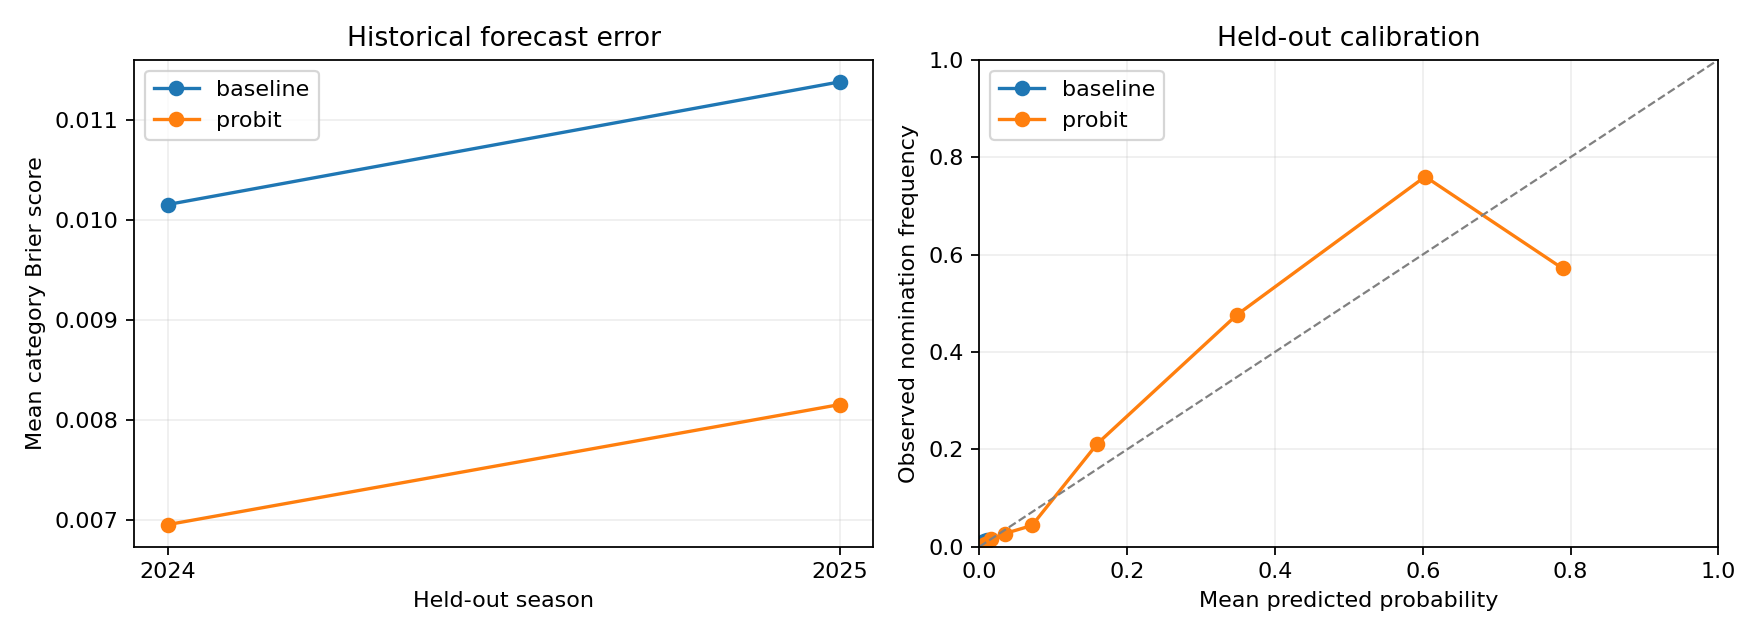

In [11]:
bins = np.array([0, 0.001, 0.005, 0.01, 0.025, 0.05, 0.10, 0.25, 0.50, 0.75, 1.0])
calibration_parts = []
for model, col in [("baseline", "p_baseline"), ("probit", "p_probit")]:
    b = backtest.assign(probability=backtest[col])
    b["bin"] = pd.cut(b.probability, bins=bins, include_lowest=True)
    table = b.groupby("bin", observed=True).agg(
        n=("nominated", "size"), mean_probability=("probability", "mean"),
        nomination_frequency=("nominated", "mean")).reset_index()
    table["model"] = model
    calibration_parts.append(table)
calibration = pd.concat(calibration_parts, ignore_index=True)
calibration.to_csv(OUTPUT / "calibration.csv", index=False)
display(calibration)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for model in ["baseline", "probit"]:
    axes[0].plot(yearly.index, yearly["brier"][model], marker="o", label=model)
    c = calibration.loc[calibration.model == model]
    axes[1].plot(c.mean_probability, c.nomination_frequency, marker="o", label=model)
axes[0].set_xticks(TEST_SEASONS)
axes[0].set(xlabel="Held-out season", ylabel="Mean category Brier score", title="Historical forecast error")
axes[1].plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
axes[1].set(xlabel="Mean predicted probability", ylabel="Observed nomination frequency",
            title="Held-out calibration", xlim=(0, 1), ylim=(0, 1))
for ax in axes:
    ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT / "backtest_and_calibration.png", dpi=160)
plt.show()

# Expected counts are sums of marginal probabilities, not forced to five.
count_check = scores[["season","cat","model","expected_nominated","actual_nominated"]].copy()
count_check["count_error"] = count_check.expected_nominated - count_check.actual_nominated
count_check.to_csv(OUTPUT / "nomination_count_checks.csv", index=False)
display(count_check)
errors = backtest.copy()
errors["squared_error"] = (errors.p_probit - errors.nominated)**2
errors["error_kind"] = np.where(errors.nominated.eq(1), "missed/underpredicted nominee", "overpredicted non-nominee")
errors = errors.sort_values("squared_error", ascending=False)
errors.head(40).to_csv(OUTPUT / "largest_errors.csv", index=False)
display(errors[["season","cat","artist","nominated","p_probit","rank_in_category","squared_error"]].head(16))


## 9. Final fit and artist shortlists for the 2027 ceremony

Each category is fitted on all labelled seasons through 2025. We retain the top five artists by posterior mean probability. The 5th and 95th percentiles describe uncertainty about an artist's **nomination probability**, not a 90% interval for the binary nomination outcome and not joint uncertainty about the shortlist. Predictions for all candidates are exported, including the equal-probability baseline.

Probabilities are not normalized across artists. Several artists can be nominated together, and more or fewer than five artists may be nominated. An artist-level shortlist cannot be interpreted as five distinct eligible works.


In [12]:
if RUN_MODE == "replay":
    forecast = read_verified("forecast_2027_all_artists.csv")
    coefficients = read_verified("final_coefficients.csv")
    final_diagnostics_df = validate_diagnostics(read_verified("diagnostics_final.csv"), [FORECAST_SEASON])
else:
    forecast_parts, coefficient_parts, final_diagnostics = [], [], []
    for cat in CATEGORIES:
        train = historical.loc[historical.cat == cat].copy()
        test = future.loc[future.cat == cat].copy()
        samples, center, scale, diagnostic = fit_probit(train, cat, FORECAST_SEASON)
        p, lo, hi = posterior_probabilities(test, samples, center, scale)
        result = test[["season", "cat", "artist_key", "artist"]].copy()
        result["p_baseline"] = float(train.nominated.mean())
        result["p_probit"], result["p_probit_q05"], result["p_probit_q95"] = p, lo, hi
        forecast_parts.append(add_provenance(result, diagnostic)); final_diagnostics.append(diagnostic)
        beta = samples["beta"].reshape(-1, len(FEATURE_NAMES))
        coefficient_parts.append(pd.DataFrame({"cat": cat, "feature": FEATURE_NAMES,
            "posterior_mean": beta.mean(axis=0), "q05": np.quantile(beta, 0.05, axis=0),
            "q95": np.quantile(beta, 0.95, axis=0), "training_scale": scale,
            "model_version": MODEL_VERSION, "data_sha256": DATA_SHA256}))
        print(f"Final {cat}: Rhat={diagnostic['max_rhat']:.3f}, ESS={diagnostic['min_ess']:.0f}", flush=True)
        del samples


    forecast = pd.concat(forecast_parts, ignore_index=True)
    coefficients = pd.concat(coefficient_parts, ignore_index=True)
    final_diagnostics_df = validate_diagnostics(pd.DataFrame(final_diagnostics).drop(columns="signature", errors="ignore"), [FORECAST_SEASON])
forecast = validate_predictions(forecast, [FORECAST_SEASON], False)
shortlists = forecast.loc[forecast.rank_in_category <= TOP_K].copy()
assert len(shortlists) == TOP_K * len(CATEGORIES)
coefficients["coefficient_unit"] = np.where(coefficients.feature.isin(["new_in_window", "ama_held", "vma_held", "iheart_held"] + [f"{a}_relevant_{k}" for a in ["ama","vma","iheart"] for k in ["nominated","winner"]]), "binary 0-to-1 on latent probit scale", "one training SD on latent probit scale")
for name, frame in [("backtest_predictions",backtest),("backtest_top5",backtest.loc[backtest.rank_in_category <= TOP_K]),("forecast_2027_all_artists",forecast),("forecast_2027_top5",shortlists),("diagnostics_backtest",backtest_diagnostics_df),("diagnostics_final",final_diagnostics_df),("final_coefficients",coefficients)]:
    frame.to_csv(OUTPUT / f"{name}.csv", index=False)
diagnostics_df = pd.concat([backtest_diagnostics_df,final_diagnostics_df], ignore_index=True)
assert len(diagnostics_df) == 24 and not diagnostics_df.duplicated(["predict_season","category"]).any()
display(shortlists[["cat","rank_in_category","artist","p_probit","p_probit_q05","p_probit_q95"]])
display(diagnostics_df[["category","predict_season","max_rhat","min_ess","divergences","depth_limit_hits"]])


,cat,rank_in_category,artist,p_probit,p_probit_q05,p_probit_q95
0,album_of_the_year,1,Taylor Swift,0.713153,0.412296,0.923381
1,album_of_the_year,2,Olivia Dean,0.532760,0.384602,0.673845
2,album_of_the_year,3,Sabrina Carpenter,0.515477,0.291208,0.729058
3,album_of_the_year,4,BTS,0.477345,0.317330,0.635641
4,album_of_the_year,5,Ariana Grande,0.474455,0.319916,0.631984
638,best_new_artist,1,Sienna Spiro,0.445215,0.261371,0.632767
639,best_new_artist,2,Ella Langley,0.327646,0.193870,0.484279
640,best_new_artist,3,STELLA LEFTY,0.243321,0.153009,0.349360
641,best_new_artist,4,Malcolm Todd,0.198913,0.123230,0.287834
642,best_new_artist,5,Bella Kay,0.187204,0.113882,0.269056


,category,predict_season,max_rhat,min_ess,divergences,depth_limit_hits
0,album_of_the_year,2024,1.004602,917.113669,0,0
1,record_of_the_year,2024,1.001858,1156.032822,0,0
2,song_of_the_year,2024,1.001725,1189.919942,0,0
3,best_new_artist,2024,1.012755,143.806836,0,0
4,pop_vocal_album,2024,1.002022,985.609800,0,0
5,pop_solo,2024,1.002780,944.912233,0,0
6,pop_duo_group,2024,1.002037,1389.334812,0,0
7,music_video,2024,1.000793,1601.580656,0,0
8,album_of_the_year,2025,1.000398,4408.274853,0,0
9,record_of_the_year,2025,1.000524,3902.885209,0,0


In [13]:
cat = "pop_vocal_album"

train = historical.loc[historical.cat == cat]
person = future.loc[
    future.cat.eq(cat)
    & future.artist.str.casefold().eq("sabrina carpenter")
]

assert len(person) == 1, "Expected one Sabrina Carpenter row"

train_features = make_features(train)
person_features = make_features(person).iloc[0]

check = pd.DataFrame({
    "Sabrina_2026": person_features,
    "train_min": train_features.min(),
    "train_max": train_features.max(),
    "train_std": train_features.std(ddof=0),
})
check["outside_train_range"] = (
    (check.Sabrina_2026 < check.train_min)
    | (check.Sabrina_2026 > check.train_max)
)

display(check)


,Sabrina_2026,train_min,train_max,train_std,outside_train_range
h_peak_strength,0.950000,0.0,1.000000,0.330018,False
log_h_entries,2.564949,0.0,4.532599,0.562928,False
log_h_weeks,4.605170,0.0,6.047372,1.369915,False
log_h_top10_weeks,1.386294,0.0,4.382027,0.588734,False
b_peak_strength,0.985000,0.0,1.000000,0.350922,False
log_b_entries,1.386294,0.0,4.488636,0.361040,False
log_b_weeks,4.691348,0.0,6.624065,1.231997,False
log_b_top10_weeks,2.708050,0.0,4.564348,0.500317,False
log_prior_noms,2.564949,0.0,3.761200,0.472210,False
log_prior_wins,1.098612,0.0,2.772589,0.225136,False


In [14]:
cat = "pop_vocal_album"
train = historical.loc[historical.cat == cat]
person = future.loc[
    future.cat.eq(cat)
    & future.artist.str.casefold().eq("sabrina carpenter")
]

raw = make_features(train)
center, scale = training_scaler(train)
z = transform(person, center, scale)[0]

# Appendix: observations supporting rare indicators.
rare = [
    "ama_relevant_nominated",
    "vma_relevant_nominated",
    "iheart_relevant_nominated",
    "iheart_relevant_winner",
]

display(pd.DataFrame({
    "feature": rare,
    "training_rows_with_1": [int(raw[f].eq(1).sum()) for f in rare],
    "nominated_among_them": [
        int(train.loc[raw[f].eq(1), "nominated"].sum()) for f in rare
    ],
}))

# Contributions to the posterior mean latent index.
contributions = (
    coefficients.loc[coefficients.cat.eq(cat)]
    .set_index("feature")
    .reindex(FEATURE_NAMES)[["posterior_mean"]]
)
contributions["transformed_value"] = z
contributions["contribution_to_eta"] = (
    contributions.posterior_mean * contributions.transformed_value
)
display(
    contributions.sort_values(
        "contribution_to_eta",
        key=lambda x: x.abs(),
        ascending=False,
    )
)


,feature,training_rows_with_1,nominated_among_them
0,ama_relevant_nominated,87,29
1,vma_relevant_nominated,169,47
2,iheart_relevant_nominated,10,2
3,iheart_relevant_winner,2,2


,posterior_mean,transformed_value,contribution_to_eta
feature,,,
log_h_weeks,-0.363279,2.719220,-0.987836
iheart_relevant_winner,0.914465,0.999920,0.914392
vma_relevant_nominated,0.874815,0.993201,0.868867
h_peak_strength,0.351938,2.262719,0.796336
log_ama_noms_total,0.050145,15.576945,0.781104
log_b_top10_weeks,0.138997,5.059460,0.703248
iheart_relevant_nominated,-0.666420,0.999598,-0.666152
log_prior_noms,0.104934,5.085062,0.533596
b_peak_strength,0.370462,1.234812,0.457451


## 10. Computed conclusions and reproducibility record
Numerical results are calculated from the current verified predictions. Probability quantiles reflect parameter uncertainty; they are not prediction sets for binary outcomes. Binary coefficients represent a 0-to-1 change on the latent probit scale; continuous coefficients represent one training standard deviation. Neither is causal.


In [15]:
b0, b1 = overall.loc["baseline","brier"], overall.loc["probit","brier"]
print(f"{DATA_VARIANT} Brier: baseline={b0:.6f}; probit={b1:.6f}; relative reduction={(b0-b1)/b0:.1%}")
print(f"Precision@5: baseline expectation={overall.loc['baseline','precision_at_5']:.6f}; probit={overall.loc['probit','precision_at_5']:.6f}")
print("Descriptive annual differences:"); display(differences)
print("Data variant:", DATA_VARIANT, "| No robust significance claim with two years. Silk Sonic remains unresolved.")
record = dict(created_at_utc=datetime.now(timezone.utc).isoformat(), data_sha256=DATA_SHA256,
    model_version=MODEL_VERSION, run_mode=RUN_MODE, scope="Stage 1 artist nominations; " + DATA_VARIANT,
    test_seasons=TEST_SEASONS, forecast_season=FORECAST_SEASON, top_k=TOP_K,
    chart_cutoff="2026-09-30", cutoff_status="proxy; historical publication dates unaudited",
    target_date="2026-11-16", eligibility_window=["2025-08-31","2026-08-28"],
    feature_names=FEATURE_NAMES, relevant_award_mapping=RELEVANT_AWARD_STEMS,
    reporting_runtime_versions=VERSIONS, seed=SEED,
    sampler_settings_by_season={str(s): dict(warmup=NUM_WARMUP,samples_per_chain=LATE_SEASON_SAMPLES if s>=2025 else NUM_SAMPLES,chains=NUM_CHAINS,target_accept=TARGET_ACCEPT,max_tree_depth=MAX_TREE_DEPTH) for s in TEST_SEASONS+[FORECAST_SEASON]},
    completed_backtest_fits=len(backtest_diagnostics_df), completed_final_fits=len(final_diagnostics_df),
    max_rhat=float(diagnostics_df.max_rhat.max()), min_ess=float(diagnostics_df.min_ess.min()),
    status=("original-data reference; two label corrections and Silk Sonic issue remain" if DATA_VARIANT=="original" else "two labels corrected; Silk Sonic unresolved"), data_variant=DATA_VARIANT)
if RUN_MODE == "replay":
    record["sampling_provenance"] = json.loads((EXPORT_INPUT/"manifest.json").read_text())["sampling_provenance"]
else:
    record["sampling_provenance"] = dict(versions=VERSIONS,backend=jax.default_backend(),chain_method=CHAIN_METHOD)
(OUTPUT/"run_metadata.json").write_text(json.dumps(record,indent=2))
manifest = dict(model_version=MODEL_VERSION,data_sha256=DATA_SHA256,test_seasons=TEST_SEASONS,forecast_season=FORECAST_SEASON,
    status=record["status"],sampling_provenance=record["sampling_provenance"],files={})
for path in sorted(OUTPUT.iterdir()):
    if path.is_file() and path.name != "manifest.json":
        manifest["files"][path.name] = dict(sha256=sha256_file(path),bytes=path.stat().st_size)
(OUTPUT/"manifest.json").write_text(json.dumps(manifest,indent=2))
print("Report saved to", OUTPUT.resolve())


original Brier: baseline=0.010766; probit=0.007557; relative reduction=29.8%
Precision@5: baseline expectation=0.010869; probit=0.587500
Descriptive annual differences:
Data variant: original | No robust significance claim with two years. Silk Sonic remains unresolved.
Report saved to /workspace/scratch/14888983397b/deliverables/stage1_package/report_outputs


,brier_improvement,precision_improvement
season,,
2024,0.003196,0.614751
2025,0.003222,0.538510


## 11. Requirements and remaining work

| Requirement | Status | Evidence / limitation |
|---|---|---|
| Target, form, horizon | Implemented with qualification | Artist nomination probability, top 5, dated final horizon; historical cutoffs remain proxies |
| Baseline + extension | Implemented | Training rate and eight Bayesian probits |
| Multiple occasions | Implemented | 2024 and 2025 held out; only two annual comparisons |
| Brier / precision@5 | Implemented on original snapshot | Recomputed tables and error examples |
| Calibration / uncertainty | Partial | Bin counts and probability quantiles; no full real-time data audit |
| Significance discussion | Implemented | Descriptive differences; insufficient annual evidence for robust significance |
| Release timing / critic reviews in proposal | Not implemented | No release-date, MusicBrainz, Album of the Year or Pitchfork predictors in the 27-feature model |
| Sources and reproducibility | Partial | Snapshot/hash, cache and code supplied; inherited extraction dates and identities incomplete |
| Corrected labels and identities | Partial | Two confirmed fixes provided separately; Silk Sonic requires consistent representation |
| Stage 2/3 | Partial, separate notebook | Chat B's known-nominee experiment; Bayesian estimation unrun; pre-nomination artist-to-work step absent |
| Report/presentation-specific instructions | Not independently checked | These separate instruction files were not attached to Chat A; do not infer their exact deadline/format |

The candidate pool omits some non-charting nominees; performer-based labels differ from formal songwriter/producer/director credits. Shared works and recurring artists violate a simple independent-row interpretation. Category predecessors are merged in Stage 1. Model refinements followed exploratory inspection, so reported accuracy should not be treated as a pristine confirmatory test. Correcting data does not guarantee higher scores.

**AI-use disclosure.** ChatGPT assisted with data auditing, code cleanup, cache verification, evaluation and explanation. The team is responsible for the data, modelling decisions, execution and interpretation. No full MCMC was run during this cleanup.
